In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LinearRegression, Ridge, Lasso, RidgeCV, LassoCV, ElasticNetCV
from sklearn.metrics import mean_squared_error, r2_score

sns.set_theme(style="whitegrid")

In [10]:
df = pd.read_csv("AmesHousing.csv")

numeric_features = [
    'Gr Liv Area', 'Total Bsmt SF', '1st Flr SF', '2nd Flr SF',
    'Garage Area', 'Garage Cars', 'Lot Area', 'Overall Qual',
    'Overall Cond', 'Year Built', 'Year Remod/Add', 'Mas Vnr Area',
    'BsmtFin SF 1', 'Bsmt Unf SF', 'Wood Deck SF', 'Open Porch SF'
]

df = df[numeric_features + ['SalePrice']].copy()

for col in numeric_features:
    if df[col].isnull().any():
        df[col] = df[col].fillna(df[col].median())

X = df.drop("SalePrice", axis=1)
y = df["SalePrice"]

X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)

scaler = StandardScaler()
X_train = scaler.fit_transform(X_train)
X_test = scaler.transform(X_test)

corr_matrix = X.corr()

print("Матрица корреляций")
display(corr_matrix.round(2))

Матрица корреляций


,Gr Liv Area,Total Bsmt SF,1st Flr SF,2nd Flr SF,Garage Area,Garage Cars,Lot Area,Overall Qual,Overall Cond,Year Built,Year Remod/Add,Mas Vnr Area,BsmtFin SF 1,Bsmt Unf SF,Wood Deck SF,Open Porch SF
Gr Liv Area,1.00,0.44,0.56,0.66,0.48,0.49,0.29,0.57,-0.12,0.24,0.32,0.40,0.21,0.24,0.25,0.34
Total Bsmt SF,0.44,1.00,0.80,-0.21,0.49,0.44,0.25,0.55,-0.17,0.41,0.30,0.39,0.54,0.41,0.23,0.25
1st Flr SF,0.56,0.80,1.00,-0.25,0.49,0.44,0.33,0.48,-0.16,0.31,0.24,0.39,0.46,0.30,0.23,0.24
2nd Flr SF,0.66,-0.21,-0.25,1.00,0.13,0.18,0.03,0.24,0.01,0.02,0.16,0.12,-0.16,0.00,0.09,0.18
Garage Area,0.48,0.49,0.49,0.13,1.00,0.89,0.21,0.56,-0.15,0.48,0.38,0.37,0.31,0.16,0.24,0.23
Garage Cars,0.49,0.44,0.44,0.18,0.89,1.00,0.18,0.60,-0.18,0.54,0.43,0.36,0.26,0.18,0.24,0.20
Lot Area,0.29,0.25,0.33,0.03,0.21,0.18,1.00,0.10,-0.03,0.02,0.02,0.13,0.19,0.02,0.16,0.10
Overall Qual,0.57,0.55,0.48,0.24,0.56,0.60,0.10,1.00,-0.09,0.60,0.57,0.42,0.28,0.27,0.26,0.30
Overall Cond,-0.12,-0.17,-0.16,0.01,-0.15,-0.18,-0.03,-0.09,1.00,-0.37,0.05,-0.13,-0.05,-0.14,0.02,-0.07
Year Built,0.24,0.41,0.31,0.02,0.48,0.54,0.02,0.60,-0.37,1.00,0.61,0.31,0.28,0.13,0.23,0.20


In [11]:
lr = LinearRegression()
lr.fit(X_train, y_train)

alphas_to_test = [0.1, 1.0, 10.0, 100.0, 1000.0, 5000.0, 10000.0, 50000.0, 100000.0]
ridge_cv = RidgeCV(alphas=alphas_to_test)
ridge_cv.fit(X_train, y_train)

lasso_cv = LassoCV(alphas=alphas_to_test, random_state=42)
lasso_cv.fit(X_train, y_train)
lasso = Lasso(alpha=50000.0, random_state=42)
lasso.fit(X_train, y_train)
l1_ratios = [0.1, 0.3, 0.5, 0.7, 0.9, 0.95, 0.99]
elastic_cv = ElasticNetCV(l1_ratio=l1_ratios, alphas=alphas_to_test, cv=5, random_state=42)
elastic_cv.fit(X_train, y_train)

print(f"alpha l2= {ridge_cv.alpha_}")
print(f"alpha l1 = {lasso_cv.alpha_}")
print(f"alpha l1/l2 = {elastic_cv.alpha_}")
print(f"Оптимальное соотношение L1/L2 (l1_ratio): {elastic_cv.l1_ratio_}")

print("Веса OLS")
print(np.round(lr.coef_, 0))
print("Веса Ridge (L2)")
print(np.round(ridge_cv.coef_, 0))
print("Веса Lasso (L1)")
print(np.round(lasso_cv.coef_, 0))
print("Веса Lasso (L1) (alpha = 50000)")
print(np.round(lasso.coef_, 0))
print("Веса ElasticNet:")
print(np.round(elastic_cv.coef_, 0))

alpha l2= 100.0
alpha l1 = 100.0
alpha l1/l2 = 1.0
Оптимальное соотношение L1/L2 (l1_ratio): 0.95
Веса OLS
[13022.  9140. 10445.  8267.  3293.  5582.  5129. 27108.  4328.  8704.
  5262.  4662.  3298. -5232.  2460.   -48.]
Веса Ridge (L2)
[13594.  7810.  9586.  7561.  3789.  5700.  4968. 25282.  4081.  8513.
  5724.  4913.  5019. -3356.  2712.   238.]
Веса Lasso (L1)
[21375.  8519.  3936.   983.  3276.  5618.  5090. 27156.  4193.  8684.
  5221.  4660.  3886. -4623.  2455.     0.]
Веса Lasso (L1) (alpha = 50000)
[    0.     0.     0.     0.     0.     0.     0. 11324.     0.     0.
     0.     0.     0.     0.     0.     0.]
Веса ElasticNet:
[13567.  7719.  9530.  7545.  3859.  5723.  4940. 25007.  4037.  8478.
  5792.  4950.  5167. -3172.  2745.   282.]


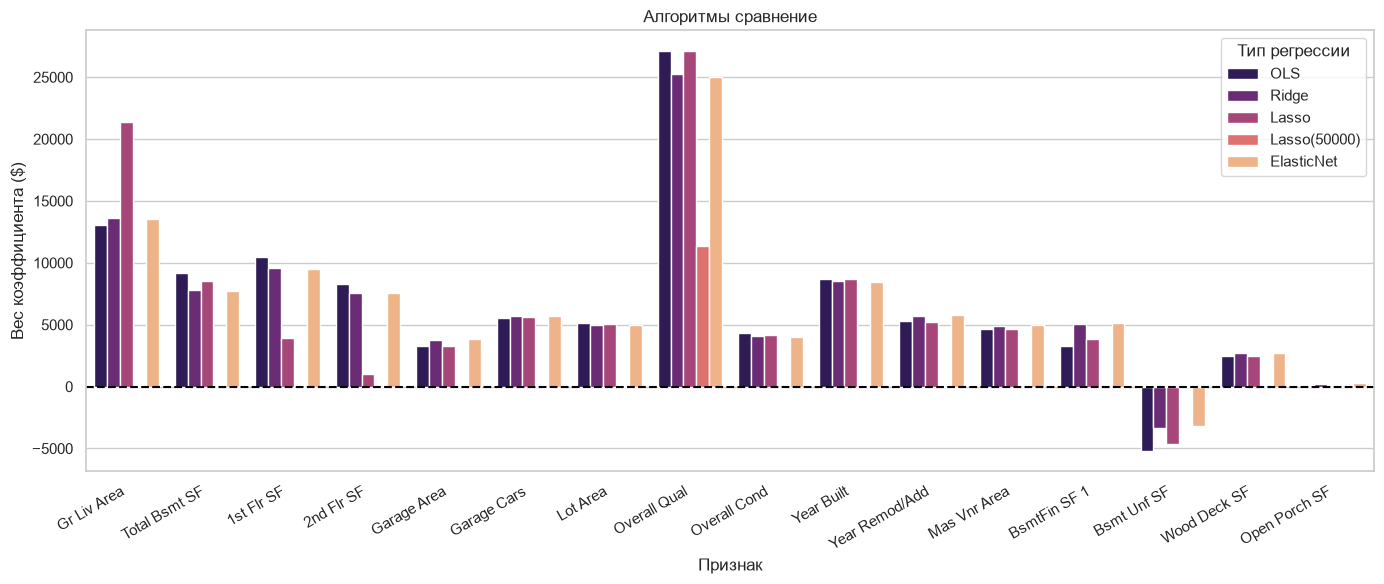

In [12]:
weights_df = pd.DataFrame(
    {
        "Признак": X.columns,
        "OLS": lr.coef_,
        "Ridge": ridge_cv.coef_,
        "Lasso": lasso_cv.coef_,
        "Lasso(50000)": lasso.coef_,
        "ElasticNet": elastic_cv.coef_
    }
)
weights_melted = weights_df.melt(
    id_vars="Признак", var_name="Модель", value_name="Влияние на цену (Вес)"
)
plt.figure(figsize=(14, 6))
sns.barplot(
    data=weights_melted,
    x="Признак",
    y="Влияние на цену (Вес)",
    hue="Модель",
    palette="magma"
)

plt.axhline(0, color="black", lw=1.5, ls="--")
plt.title("Алгоритмы сравнение")
plt.ylabel("Вес коэффициента ($)", fontsize=12)
plt.xticks(rotation=30, ha="right")
plt.legend(title="Тип регрессии")
plt.tight_layout()
plt.show()

In [13]:
print(f"R2 для OLS: {r2_score(y_test, lr.predict(X_test)):.4f}")
print(f"R2 для Ridge: {r2_score(y_test, ridge_cv.predict(X_test)):.4f}")
print(f"R2 для Lasso: {r2_score(y_test, lasso_cv.predict(X_test)):.4f}")
print(f"R2 для Lasso(50000): {r2_score(y_test, lasso.predict(X_test)):.4f}")
print(f"R2 для ElasticNet: {r2_score(y_test, elastic_cv.predict(X_test)):.4f}")

R2 для OLS: 0.8289
R2 для Ridge: 0.8283
R2 для Lasso: 0.8288
R2 для Lasso(50000): 0.1902
R2 для ElasticNet: 0.8281
